# plutovizu — Diagrammes et infographie

API chaînable : chaque méthode retourne le graphique, on enchaîne les appels et on termine par `.show()`. Le thème **editorial** est appliqué dès l'import. Fiches détaillées (données attendues, paramètres) dans la [documentation](https://mr-kam.github.io/plutovizu/).

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plutovizu import (Chart, cm, get_fonts, list_themes, set_theme, texture_class,
                       theme_context)

# Taille par défaut d'un graphique : 16 × 10 cm ; cm(largeur, hauteur) pour une autre taille.
# Export (save) : 400 dpi par défaut.

## Diagrammes

Un diagramme se décrit par un tableau de **liens** : une ligne par flux, par flèche ou par message (comme une ligne `A --> B` de Mermaid). Données **fictives**.

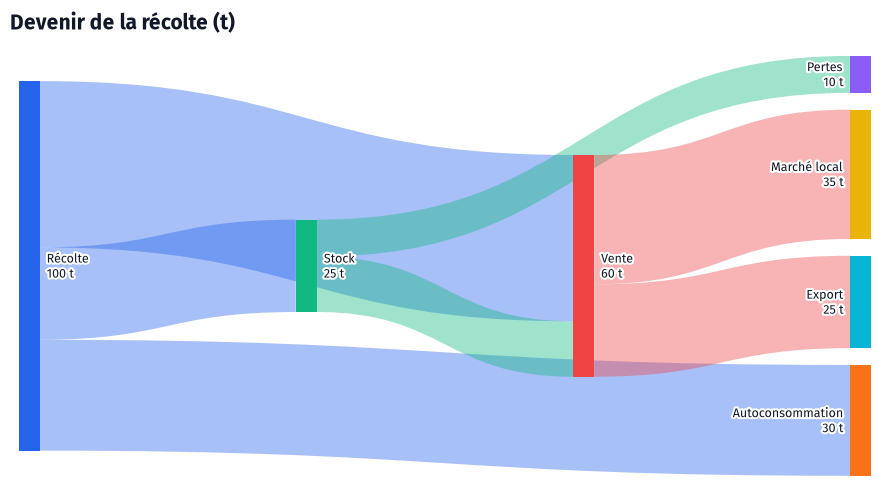

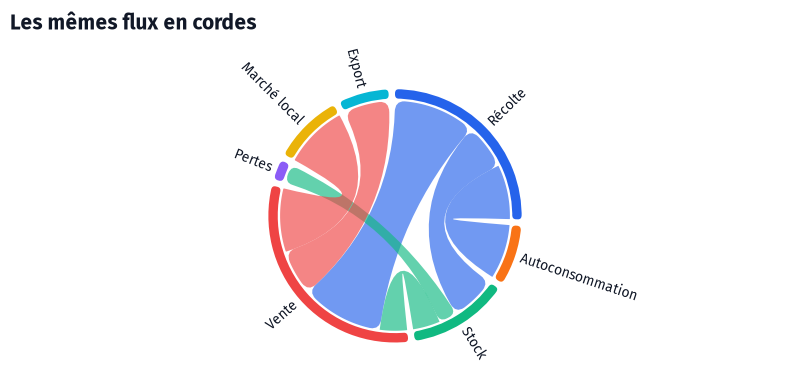

In [2]:
devenir = pd.DataFrame([
    ('Récolte', 'Autoconsommation', 30), ('Récolte', 'Stock', 25), ('Récolte', 'Vente', 45),
    ('Stock', 'Vente', 15), ('Stock', 'Pertes', 10), ('Vente', 'Marché local', 35),
    ('Vente', 'Export', 25)], columns=['de', 'vers', 'tonnes'])

(Chart(devenir, figsize=(9, 5))
    .sankey('de', 'vers', 'tonnes', unit=' t')
    .title('Devenir de la récolte (t)')
    .tight_layout()
    .show())

(Chart(devenir, figsize=(8, 4))
    .chord('de', 'vers', 'tonnes')
    .title('Les mêmes flux en cordes')
    .tight_layout()
    .show())

### Venn : une colonne booléenne par ensemble (une ligne par ménage)

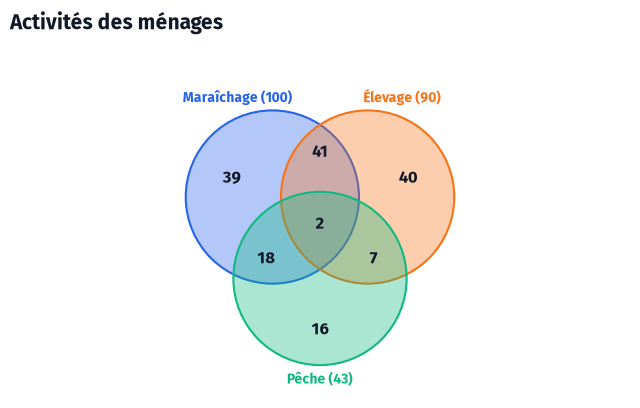

,zone,n
0,Maraîchage,39
1,Élevage,40
2,Pêche,16
3,Maraîchage ∩ Élevage,41
4,Maraîchage ∩ Pêche,18
5,Élevage ∩ Pêche,7
6,Maraîchage ∩ Élevage ∩ Pêche,2


In [3]:
rng_v = np.random.default_rng(1)
menages = pd.DataFrame({'Maraîchage': rng_v.random(200) < 0.5,
                        'Élevage': rng_v.random(200) < 0.4,
                        'Pêche': rng_v.random(200) < 0.25})
chart = Chart(menages, figsize=(8, 4.5)).venn(['Maraîchage', 'Élevage', 'Pêche']).title('Activités des ménages')
chart.show()
chart.venn_table

### Logigramme, organigramme, séquence

Un nom finissant par « ? » est une décision (losange) ; `label` écrit sur les flèches ; les boucles contournent les boîtes.

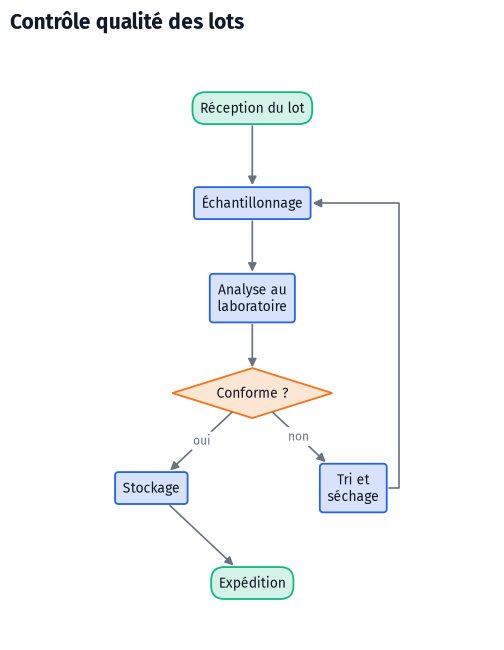

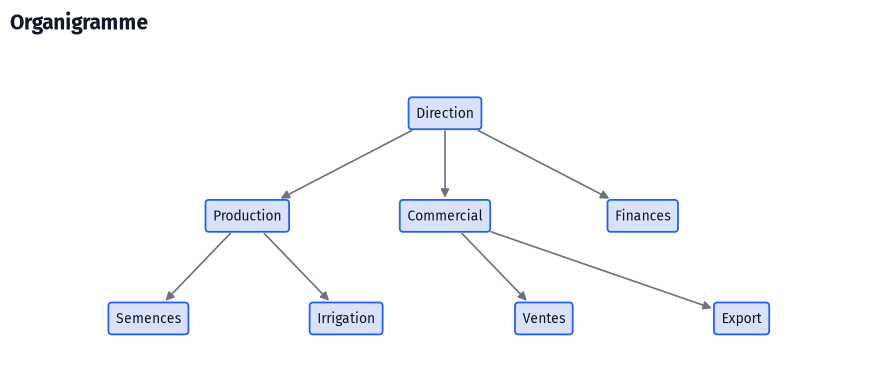

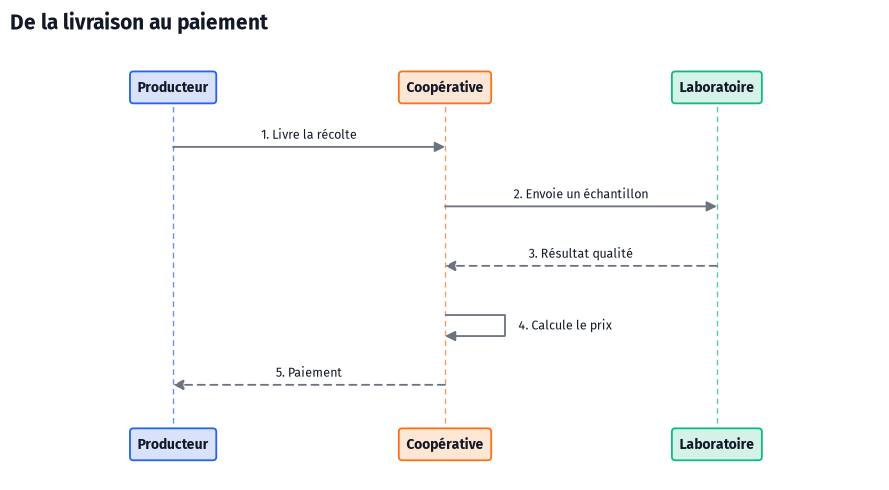

In [4]:
controle = pd.DataFrame([
    ('Réception du lot', 'Échantillonnage', None),
    ('Échantillonnage', 'Analyse au\nlaboratoire', None),
    ('Analyse au\nlaboratoire', 'Conforme ?', None),
    ('Conforme ?', 'Stockage', 'oui'), ('Conforme ?', 'Tri et\nséchage', 'non'),
    ('Tri et\nséchage', 'Échantillonnage', None), ('Stockage', 'Expédition', None)],
    columns=['de', 'vers', 'si'])
(Chart(controle, figsize=(6, 7.5))
    .flowchart('de', 'vers', label='si', shapes={'Réception du lot': 'stadium', 'Expédition': 'stadium'})
    .title('Contrôle qualité des lots')
    .tight_layout()
    .show())

organigramme = pd.DataFrame([('Direction', 'Production'), ('Direction', 'Commercial'),
    ('Direction', 'Finances'), ('Production', 'Semences'), ('Production', 'Irrigation'),
    ('Commercial', 'Ventes'), ('Commercial', 'Export')], columns=['responsable', 'service'])
Chart(organigramme, figsize=(9, 4)).flowchart('responsable', 'service').title('Organigramme').tight_layout().show()

paiement = pd.DataFrame([
    ('Producteur', 'Coopérative', 'Livre la récolte', False),
    ('Coopérative', 'Laboratoire', 'Envoie un échantillon', False),
    ('Laboratoire', 'Coopérative', 'Résultat qualité', True),
    ('Coopérative', 'Coopérative', 'Calcule le prix', False),
    ('Coopérative', 'Producteur', 'Paiement', True)], columns=['de', 'vers', 'message', 'reponse'])
(Chart(paiement, figsize=(9, 5))
    .sequence_diagram('de', 'vers', 'message', dashed='reponse', numbered=True)
    .title('De la livraison au paiement')
    .tight_layout()
    .show())

## Infographie

Police (`font`, Google Fonts), fond (`background`), couleurs (`set_colors`, `colors=`, `cmap=`), titre et sous-titre (`title`, `subtitle`), annotations fléchées (`annotation`) et source (`caption`). Exemples d'après la [Python Graph Gallery](https://python-graph-gallery.com).

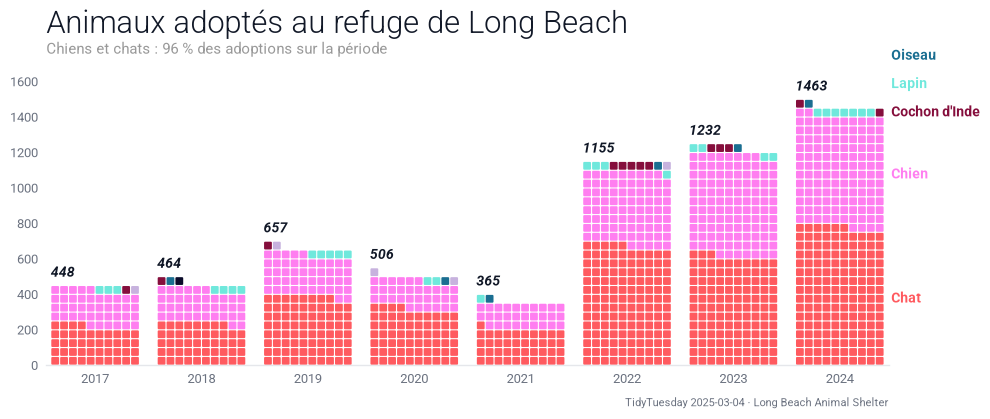

In [5]:
adoptions = pd.DataFrame({
    'annee': range(2017, 2025),
    'Chat': [222, 238, 391, 320, 207, 675, 616, 779],
    'Chien': [205, 191, 234, 158, 145, 422, 575, 632],
    'Lapin': [13, 22, 25, 9, 3, 22, 20, 36],
    "Cochon d'Inde": [3, 3, 3, 2, 2, 23, 14, 8],
    'Oiseau': [1, 4, 0, 7, 4, 6, 5, 6],
    'Reptile': [0, 5, 1, 2, 2, 1, 2, 1],
    'Autre': [4, 1, 3, 8, 2, 6, 0, 1],
}).melt('annee', var_name='animal', value_name='n')

(Chart(adoptions, figsize=(10, 6.5))
    .font('Roboto')
    .set_colors(['#ff5a5f', '#ff7ef0', '#6fe8dc', '#850e3c', '#1a6e91', '#c7b2de', '#0b0b2a'])
    .waffle('animal', 'n', x='annee', unit=5, direct_labels=True)
    .title('Animaux adoptés au refuge de Long Beach', fontsize=22, fontweight=300)
    .subtitle('Chiens et chats : 96 % des adoptions sur la période', color='#999999')
    .caption('TidyTuesday 2025-03-04 · Long Beach Animal Shelter')
    .tight_layout()
    .show())

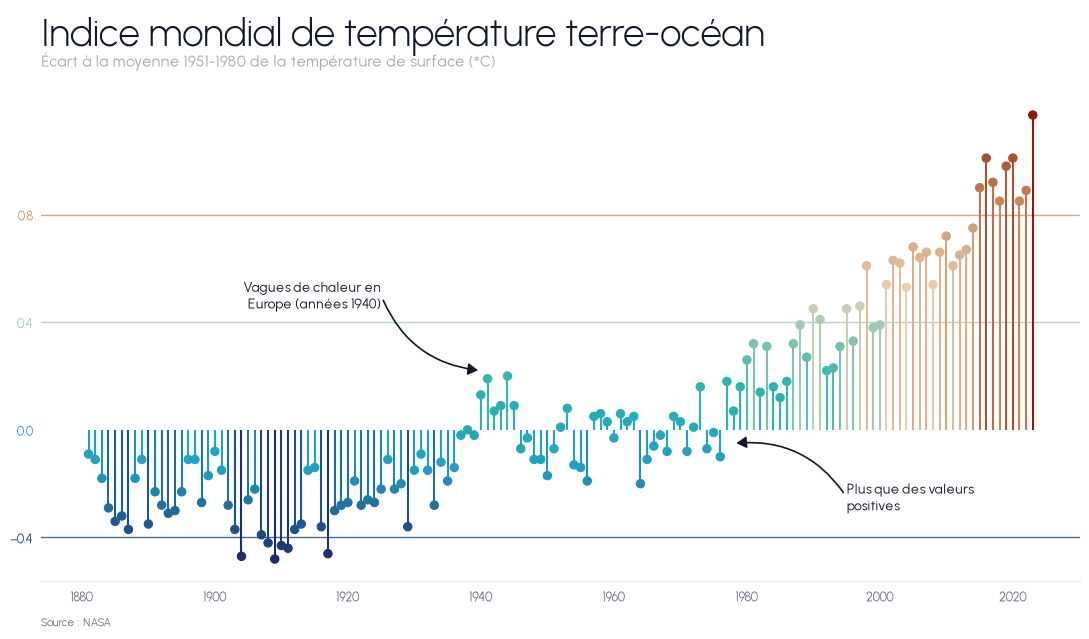

In [6]:
temperature = pd.read_csv('https://raw.githubusercontent.com/holtzy/The-Python-Graph-Gallery/'
                          'master/static/data/temperature-variation.csv')
(Chart(temperature, figsize=(11, 6.5))
    .font('Urbanist')
    .stem('Year', 'Change', hlines=[-0.4, 0.4, 0.8],
          cmap=['#1d2a6b', '#1f9fc4', '#2ab7b0', '#e9d3b4', '#c98b5e', '#8c1c03'])
    .title('Indice mondial de température terre-océan', fontsize=28, fontweight=300)
    .subtitle('Écart à la moyenne 1951-1980 de la température de surface (°C)', color='#aaaaaa')
    .labels('', '')
    .annotation('Vagues de chaleur en\nEurope (années 1940)', xy=(1940, 0.22), xytext=(1925, 0.5))
    .annotation('Plus que des valeurs\npositives', xy=(1978, -0.05), xytext=(1995, -0.25))
    .caption('Source : NASA', loc='left')
    .tight_layout()
    .show())

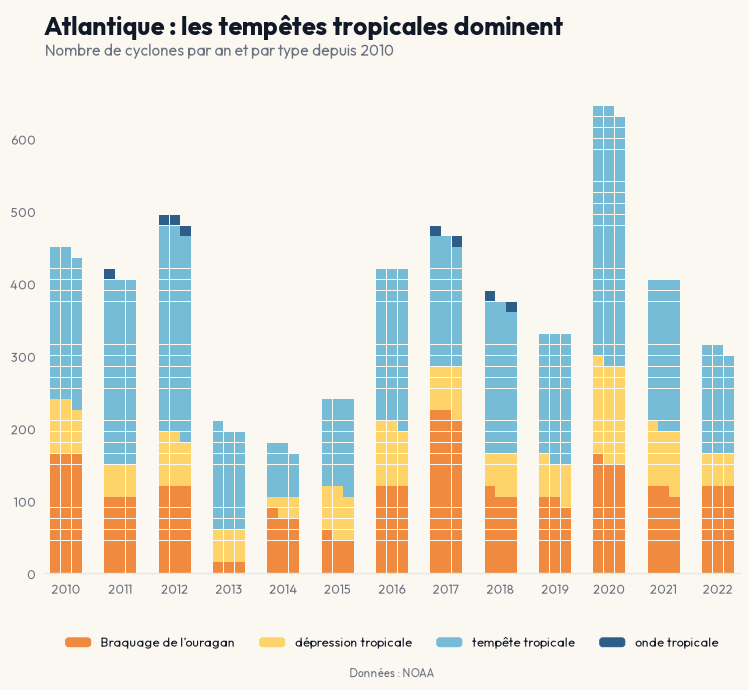

In [7]:
cyclones = pd.read_csv('https://raw.githubusercontent.com/holtzy/The-Python-Graph-Gallery/'
                       'master/static/data/storms.csv')
(Chart(cyclones, figsize=(16, 7))
    .font('Outfit')
    .background('#fbf8f1')
    .waffle('status', 'n', x='year', unit=5, columns=3, gap=0.06, rounding=0, totals=False,
            order=['hurricane', 'tropical depression', 'tropical storm', 'tropical wave'],
            colors={'hurricane': '#f08a3e', 'tropical depression': '#fdd36a',
                    'tropical storm': '#76bcd6', 'tropical wave': '#2f5d8a'})
    .title('Atlantique : les tempêtes tropicales dominent', fontsize=18, fontweight='bold')
    .subtitle('Nombre de cyclones par an et par type depuis 2010')
    .set_legend(location='below')
    .caption('Données : NOAA', loc='center')
    .tight_layout()
    .translate("fr", from_='online',source="en")
    .show())
set_theme()   # police et thème par défaut pour la suite

### Courbes étiquetées et histogramme logarithmique

Données simulées dans [`datasets/`](datasets/). `line(direct_labels=True)` pose le nom de chaque série sur sa courbe, `direct_labels='end'` écrit la dernière valeur au bout ; `tick_format(y='{:.0f} %')` formate les graduations ; `histogram(log=True, hue=…, smooth=True)` empile les groupes dans des classes égales en échelle log et ajoute la courbe lissée.

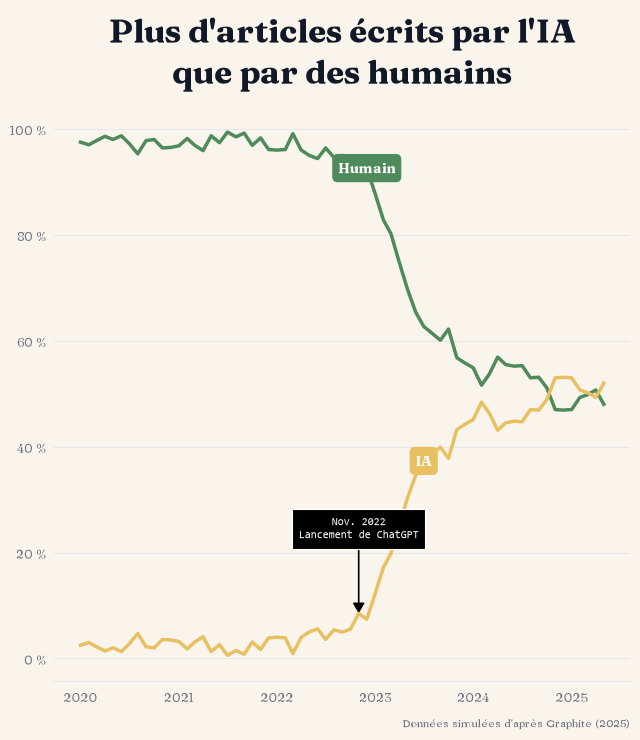

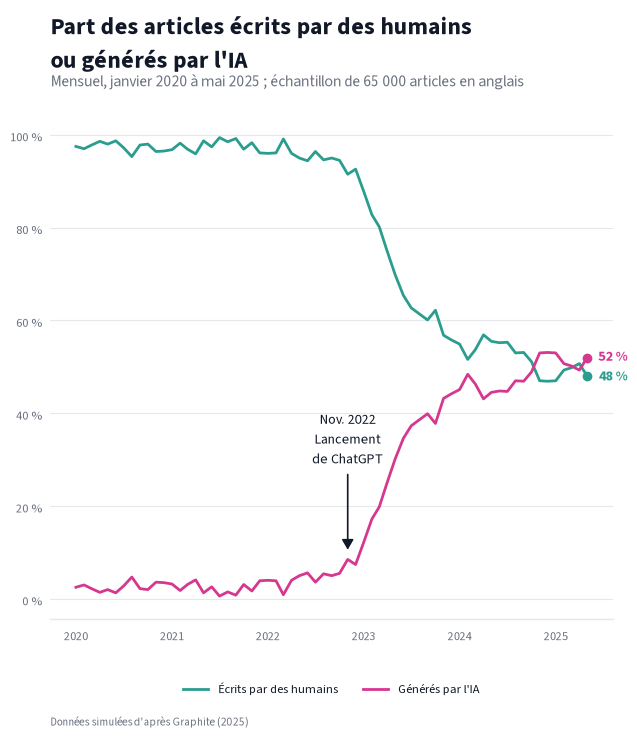

In [8]:
articles = pd.read_csv('datasets/articles_ia.csv', parse_dates=['mois'])
chatgpt = pd.Timestamp('2022-11-01')

(Chart(articles.rename(columns={'humain': 'Humain', 'ia': 'IA'}), figsize=(6.5, 7.5))
    .font('Fraunces')
    .background('#faf5ec')
    .set_colors(['#4f8a5b', '#e8c062'])
    .line('mois', ['Humain', 'IA'], marker='', linewidth=2.5, direct_labels=True)
    .tick_format(y='{:.0f} %')
    .annotation('Nov. 2022\nLancement de ChatGPT', xy=(chatgpt, 8), xytext=(chatgpt, 22), radius=0,
                color='white', arrow_color='black', fontfamily='monospace', fontsize=8,
                bbox=dict(boxstyle='square,pad=0.6', facecolor='black'))
    .title("Plus d'articles écrits par l'IA\nque par des humains", fontsize=24, loc='center')
    .labels('', '')
    .caption("Données simulées d'après Graphite (2025)")
    .tight_layout()
    .show())

(Chart(articles.rename(columns={'humain': 'Écrits par des humains', 'ia': "Générés par l'IA"}),
       figsize=(6.5, 7.5))
    .font('Source Sans 3')
    .set_colors(['#2a9d8f', '#d6378f'])
    .line('mois', ['Écrits par des humains', "Générés par l'IA"], marker='',
          direct_labels='end', value_format='{:.0f} %')
    .tick_format(y='{:.0f} %')
    .annotation('Nov. 2022\nLancement\nde ChatGPT', xy=(chatgpt, 10), xytext=(chatgpt, 28), radius=0)
    .title("Part des articles écrits par des humains\nou générés par l'IA", loc='left', fontsize=17)
    .subtitle('Mensuel, janvier 2020 à mai 2025 ; échantillon de 65 000 articles en anglais')
    .labels('', '')
    .set_legend(location='below')
    .caption("Données simulées d'après Graphite (2025)", loc='left')
    .tight_layout()
    .show())

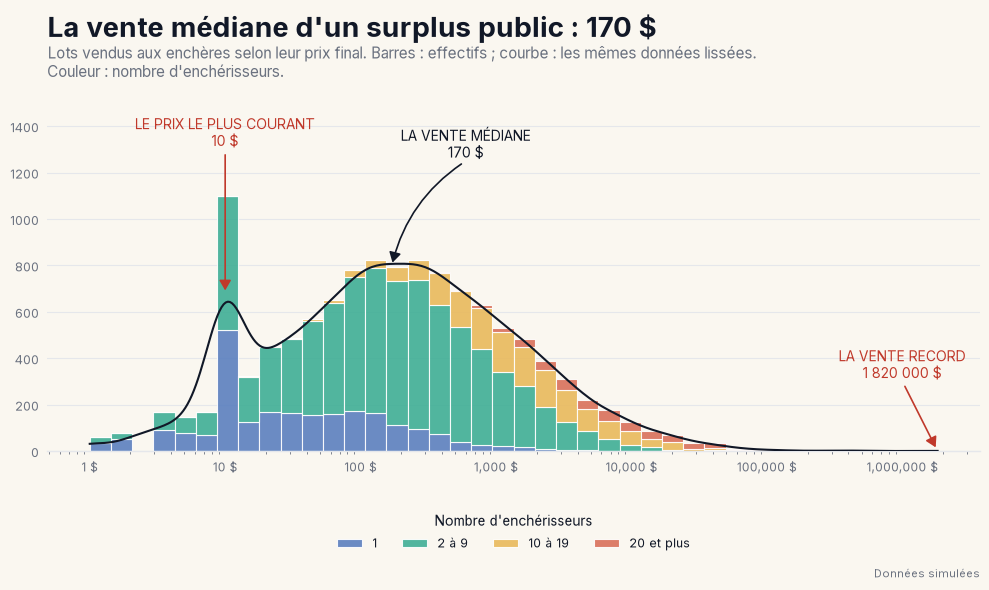

In [9]:
encheres = pd.read_csv('datasets/encheres_publiques.csv')

(Chart(encheres, figsize=(10, 6))
    .font('Inter')
    .background('#faf7f0')
    .set_colors(['#5b7fbf', '#3fae95', '#e9b95c', '#d9705a'])
    .histogram('prix', bins=40, log=True, hue='classe', order=['1', '2 à 9', '10 à 19', '20 et plus'],
               smooth=True, alpha=0.9)
    .rounded(0)
    .set_limits(ylim=(0, 1500))
    .tick_format(x='{:,.0f} $')
    .annotation('LE PRIX LE PLUS COURANT\n10 $', xy=(10, 680), xytext=(10, 1300), radius=0, color='#c0392b')
    .annotation('LA VENTE MÉDIANE\n170 $', xy=(170, 800), xytext=(600, 1250), radius=0.2)
    .annotation('LA VENTE RECORD\n1 820 000 $', xy=(1.8e6, 5), xytext=(1e6, 300), radius=0, color='#c0392b')
    .title("La vente médiane d'un surplus public : 170 $", loc='left', fontsize=20, fontweight='bold')
    .subtitle('Lots vendus aux enchères selon leur prix final. Barres : effectifs ; courbe : les mêmes '
              "données lissées.\nCouleur : nombre d'enchérisseurs.")
    .labels('', '')
    .set_legend(location='below', title="Nombre d'enchérisseurs")
    .caption('Données simulées')
    .tight_layout()
    .show())
set_theme()   # police et thème par défaut pour la suite

### L'IA en chiffres (2025-2026)

Statistiques publiées par Microsoft (*Global AI Diffusion*), Eurostat (`isoc_eb_ai`) et le Stanford *AI Index 2026*, dans [`datasets/`](datasets/). Les valeurs Microsoft autres que l'Afrique du Sud (23,9 %) et la Côte d'Ivoire (13,7 %) sont lues sur les graphiques publiés. `pct` écrit les pourcentages avec une virgule décimale ; `color=[…]` met une barre en valeur ; `Chart(theme=…)` change le thème d'un seul graphique.

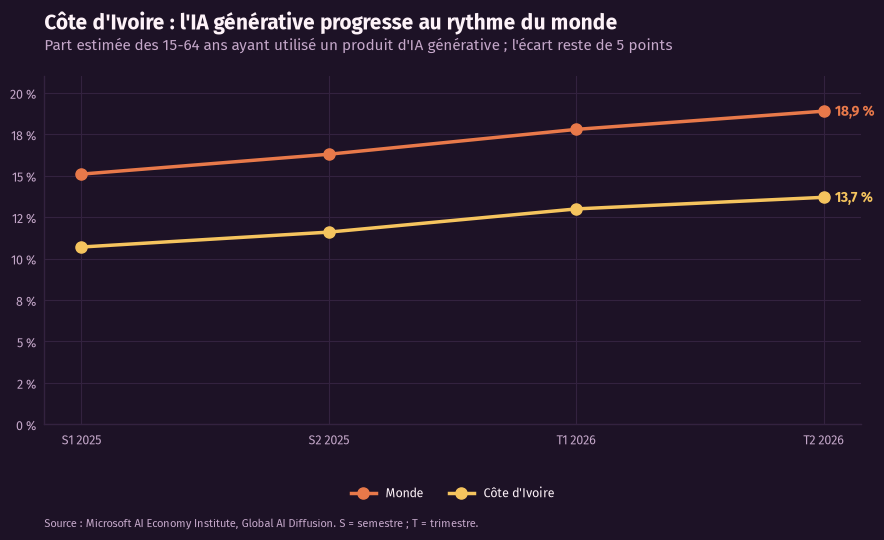

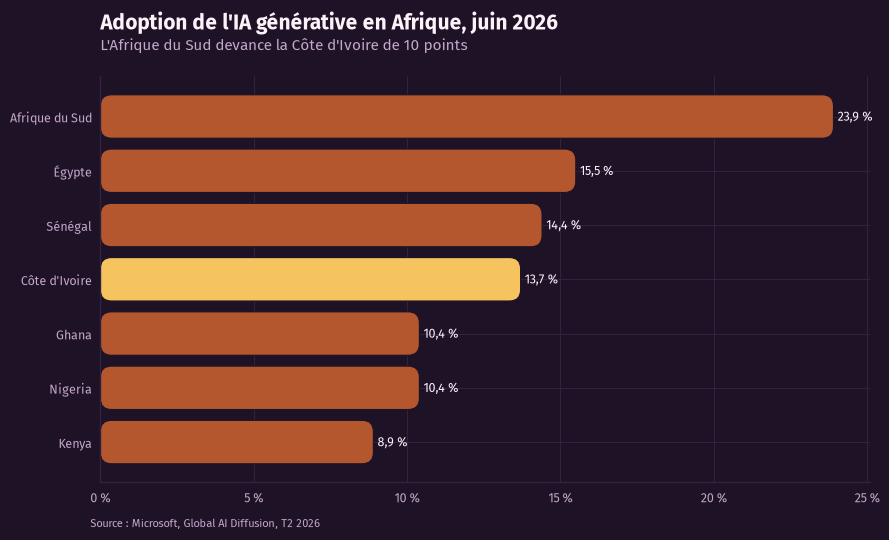

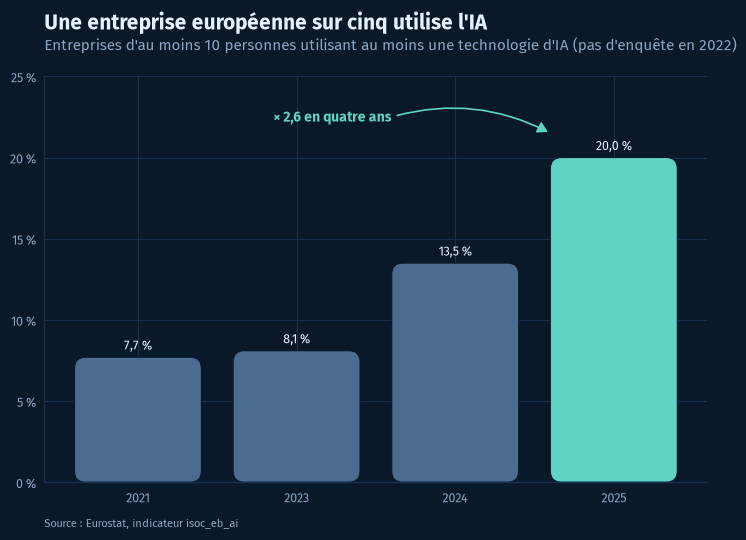

In [10]:
pct = lambda v: f'{v:.1f} %'.replace('.', ',')
usage = pd.read_csv('datasets/ia_generative_monde_civ.csv')

(Chart(usage, figsize=(9, 5.5), theme='sunset')
    .set_colors(['#e8794a', '#f5c45e'])
    .line('periode', ['Monde', "Côte d'Ivoire"], linewidth=2.5, markersize=8,
          direct_labels='end', value_format=pct)
    .set_limits(ylim=(0, 21))
    .tick_format(y='{:.0f} %')
    .title("Côte d'Ivoire : l'IA générative progresse au rythme du monde", loc='left',
           fontweight='bold')
    .subtitle("Part estimée des 15-64 ans ayant utilisé un produit d'IA générative ; l'écart reste de 5 points")
    .labels('', '')
    .set_legend(location='below')
    .caption('Source : Microsoft AI Economy Institute, Global AI Diffusion. S = semestre ; T = trimestre.',
             loc='left')
    .tight_layout()
    .show())

afrique = pd.read_csv('datasets/ia_adoption_afrique_2026.csv').iloc[::-1]   # le plus grand en haut
(Chart(afrique, figsize=(9, 5.5), theme='sunset')
    .bar('pays', 'adoption', horizontal=True, alpha=1, show_values=True, value_format=pct,
         color=['#f5c45e' if p == "Côte d'Ivoire" else '#b4572e' for p in afrique['pays']])
    .tick_format(x='{:.0f} %')
    .title("Adoption de l'IA générative en Afrique, juin 2026", loc='left', fontweight='bold')
    .subtitle("L'Afrique du Sud devance la Côte d'Ivoire de 10 points")
    .labels('', '')
    .caption('Source : Microsoft, Global AI Diffusion, T2 2026', loc='left')
    .tight_layout()
    .show())

entreprises = pd.read_csv('datasets/eurostat_entreprises_ia.csv', dtype={'annee': str})
(Chart(entreprises, figsize=(8, 5.5), theme='ocean')
    .bar('annee', 'part', alpha=1, show_values=True, value_format=pct,
         color=['#4b6b8f', '#4b6b8f', '#4b6b8f', '#5fd3c6'])
    .set_limits(ylim=(0, 25))
    .tick_format(y='{:.0f} %')
    .annotation('× 2,6 en quatre ans', xy=(2.6, 21.5), xytext=(1.6, 22.5), radius=-0.2,
                fontweight='bold', color='#5fd3c6')
    .title("Une entreprise européenne sur cinq utilise l'IA", loc='left', fontweight='bold')
    .subtitle("Entreprises d'au moins 10 personnes utilisant au moins une technologie d'IA "
              "(pas d'enquête en 2022)")
    .labels('', '')
    .caption('Source : Eurostat, indicateur isoc_eb_ai', loc='left')
    .tight_layout()
    .show())

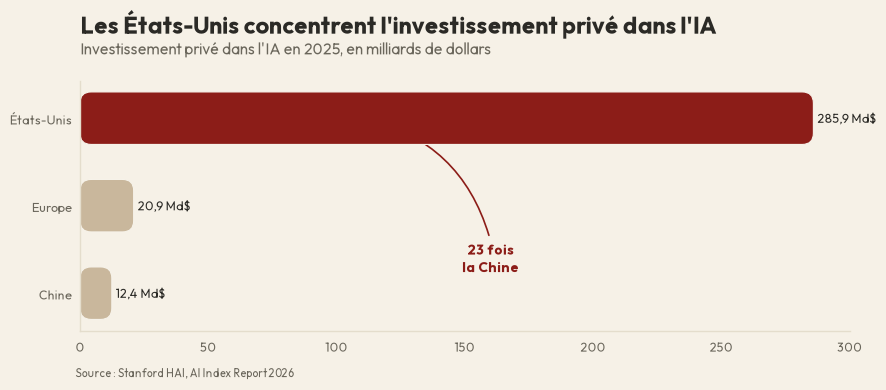

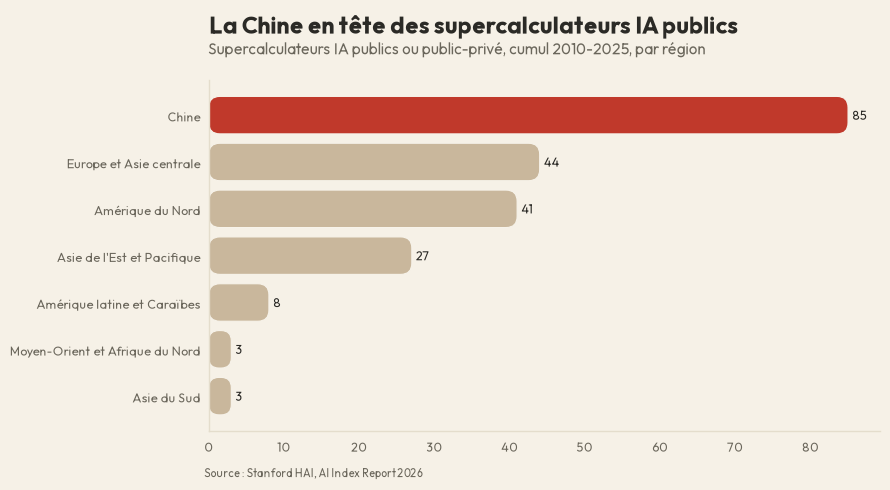

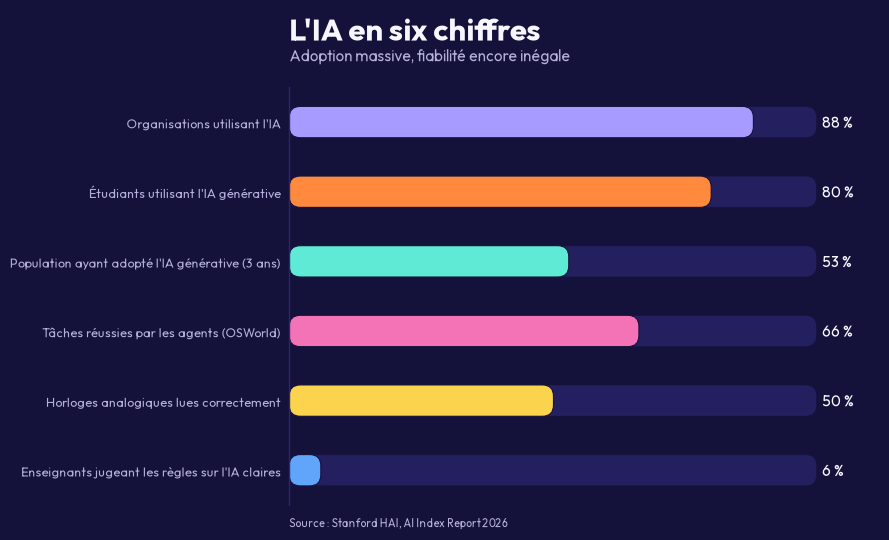

In [11]:
milliards = lambda v: f'{v:.1f} Md$'.replace('.', ',')
investissement = pd.read_csv('datasets/ai_index_2026_investissement.csv').iloc[::-1]
(Chart(investissement, figsize=(9, 4), theme='paper')
    .font('Outfit')
    .background('#f6f1e7')
    .bar('region', 'milliards_usd', horizontal=True, alpha=1, width=0.6, show_values=True,
         value_format=milliards, color=['#c9b79c', '#c9b79c', '#8c1d18'])
    .grid(False)
    .tick_format(x='{:.0f}')
    .annotation('23 fois\nla Chine', xy=(110, 2), xytext=(160, 0.6), radius=0.3, fontweight='bold',
                color='#8c1d18')
    .title("Les États-Unis concentrent l'investissement privé dans l'IA", loc='left',
           fontsize=17, fontweight='bold')
    .subtitle("Investissement privé dans l'IA en 2025, en milliards de dollars")
    .labels('', '')
    .caption('Source : Stanford HAI, AI Index Report 2026', loc='left')
    .tight_layout()
    .show())

supercalculateurs = pd.read_csv('datasets/ai_index_2026_supercalculateurs.csv').iloc[::-1]
(Chart(supercalculateurs, figsize=(9, 5), theme='paper')
    .font('Outfit')
    .background('#f6f1e7')
    .bar('region', 'supercalculateurs', horizontal=True, alpha=1, show_values=True,
         color=['#c9b79c'] * 6 + ['#c0392b'])
    .grid(False)
    .tick_format(x='{:.0f}')
    .title('La Chine en tête des supercalculateurs IA publics', loc='left',
           fontsize=17, fontweight='bold')
    .subtitle('Supercalculateurs IA publics ou public-privé, cumul 2010-2025, par région')
    .labels('', '')
    .caption('Source : Stanford HAI, AI Index Report 2026', loc='left')
    .tight_layout()
    .show())

chiffres = pd.read_csv('datasets/ai_index_2026_chiffres_cles.csv')
(Chart(chiffres, figsize=(9, 5.5), theme='pluto')
    .font('Outfit')
    .progress_bar('pourcentage', labels='indicateur', height=0.45)
    .title("L'IA en six chiffres", loc='left', fontsize=22, fontweight='bold')
    .subtitle('Adoption massive, fiabilité encore inégale')
    .caption('Source : Stanford HAI, AI Index Report 2026', loc='left')
    .tight_layout()
    .show())
set_theme()   # police et thème par défaut pour la suite